# Historia 4 — Ilu pracowników trzeba przebadać?

Firma ma **50 000 pracowników**. Dzielimy ich na trzy grupy wiekowe:

| Grupa | Liczba pracowników | Odchylenie wieku |
|---|---:|---:|
| 18–30 lat | 20 000 | 5 lat |
| 31–50 lat | 20 000 | 6 lat |
| 51 lat i więcej | 10 000 | 7 lat |

**Cel:** ustalić potrzebną liczbę ankietowanych przy **95% poziomie ufności** i dokładności **do 1 roku**.

Pokażemy dwa sposoby liczenia: osobno dla każdej grupy (jak w przykładach z PDF-u) oraz dla jednej średniej wieku całej firmy. To dwa różne cele badania.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [8]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

### Krok 1. Wprowadzamy dane
Zapisujemy liczbę pracowników w każdej grupie, różnice wieku i wymaganą dokładność.

In [9]:
nazwy4 = ["Młodzi (18–30)", "W średnim wieku (31–50)", "Starsi (51+)"]
populacje4 = np.array([20_000, 20_000, 10_000], dtype=int)
sigmy4 = np.array([5.0, 6.0, 7.0])
N4 = int(populacje4.sum())
E4 = 1.0
z4 = stats.norm.ppf(0.975)
wagi4 = populacje4 / N4

print(f"Łączna populacja: {N4:,}")
print(f"Wartość Z: {z4:.4f}")
print("Udziały grup w populacji:", np.round(wagi4, 2))

Łączna populacja: 50,000
Wartość Z: 1.9600
Udziały grup w populacji: [0.4 0.4 0.2]


### Krok 2. Liczymy próbę osobno dla każdej grupy
Sprawdzamy, ile osób potrzeba w każdej grupie wiekowej, jeśli chcemy uzyskać wymaganą dokładność dla każdej grupy osobno. Potem sumujemy wyniki.

In [10]:
n_warstwy4 = np.ceil((z4**2 * sigmy4**2) / E4**2).astype(int)
n_pdf4 = int(n_warstwy4.sum())

tabela4_pdf = pd.DataFrame({
    "Grupa wiekowa": nazwy4,
    "Liczebność populacji": populacje4,
    "Liczebność próby (osobna dokładność ±1 rok)": n_warstwy4,
})
display(tabela4_pdf)
print(f"Łącznie według sumowania wymagań poszczególnych warstw: {n_pdf4} osób")

,Grupa wiekowa,Liczebność populacji,Liczebność próby (osobna dokładność ±1 rok)
0,Młodzi (18–30),20000,97
1,W średnim wieku (31–50),20000,139
2,Starsi (51+),10000,189


Łącznie według sumowania wymagań poszczególnych warstw: 425 osób


### Krok 3. Przygotowujemy drugi sposób
Teraz zajmiemy się jednym wynikiem dla całej firmy. Potrzebujemy prostych funkcji, które podzielą ankietowanych między grupy i sprawdzą dokładność.

In [11]:
def alokuj_proporcjonalnie(n, populacje):
    # Dzielimy osoby odpowiednio do wielkości grup.
    populacje = np.asarray(populacje, dtype=int)
    udzialy = populacje / populacje.sum()
    idealne = n * udzialy
    przydzial = np.floor(idealne).astype(int)
    brakuje = n - przydzial.sum()
    kolejnosc = np.argsort(-(idealne - przydzial), kind="stable")
    przydzial[kolejnosc[:brakuje]] += 1
    return przydzial


def margines_warstwowy(przydzial, populacje, wariancje, z):
    # Sprawdzamy dokładność wyniku dla całej populacji.
    przydzial = np.asarray(przydzial, dtype=float)
    populacje = np.asarray(populacje, dtype=float)
    wariancje = np.asarray(wariancje, dtype=float)
    if np.any(przydzial == 0) or np.any(przydzial > populacje):
        return float("inf")
    wagi = populacje / populacje.sum()
    wariancja_estymatora = np.sum(wagi**2 * (1/przydzial - 1/populacje) * wariancje)
    return z * np.sqrt(max(wariancja_estymatora, 0))

print("Przykładowy przydział 100 osób:", alokuj_proporcjonalnie(100, populacje4))

Przykładowy przydział 100 osób: [40 40 20]


### Krok 4. Szukamy liczby osób dla całej firmy
Program sprawdza, jak mała może być próba, jeśli chcemy oszacować tylko średni wiek wszystkich pracowników razem. Uwzględnia też wielkość każdej grupy.

In [12]:
def minimalna_proba_proporcjonalna(populacje, wariancje, z, E):
    # Szukamy potrzebnej liczby osób.
    N = int(np.sum(populacje))
    wagi = np.asarray(populacje) / N
    A = np.sum(wagi * np.asarray(wariancje))
    n0 = (z**2 * A) / E**2
    n_fpc = n0 / (1 + n0 / N)
    n = max(len(populacje), math.ceil(n_fpc))

    def blad_dla(n_test):
        alokacja = alokuj_proporcjonalnie(n_test, populacje)
        return margines_warstwowy(alokacja, populacje, wariancje, z)

    while blad_dla(n) > E:
        n += 1
    while n > len(populacje) and blad_dla(n - 1) <= E:
        n -= 1
    return n0, n_fpc, n, alokuj_proporcjonalnie(n, populacje), blad_dla(n)

n0_4, nfpc_4, n_global4, podzial4, margines_global4 = minimalna_proba_proporcjonalna(
    populacje4, sigmy4**2, z4, E4
)

print(f"Przed korektą FPC (n0): {n0_4:.2f}")
print(f"Po korekcie FPC (przed zaokrągleniem): {nfpc_4:.2f}")
print(f"Minimalna liczba osób przy alokacji proporcjonalnej: {n_global4}")
print(f"Przydział na warstwy: {dict(zip(nazwy4, podzial4))}")
print(f"Rzeczywisty margines błędu średniej łącznej: ±{margines_global4:.4f} roku")
assert sum(podzial4) == n_global4 and margines_global4 <= E4

Przed korektą FPC (n0): 131.38
Po korekcie FPC (przed zaokrągleniem): 131.03
Minimalna liczba osób przy alokacji proporcjonalnej: 132
Przydział na warstwy: {'Młodzi (18–30)': np.int64(53), 'W średnim wieku (31–50)': np.int64(53), 'Starsi (51+)': np.int64(26)}
Rzeczywisty margines błędu średniej łącznej: ±0.9972 roku


### Krok 5. Porównujemy oba wyniki
Na wykresie widać, ile osób trzeba zapytać według obu sposobów.

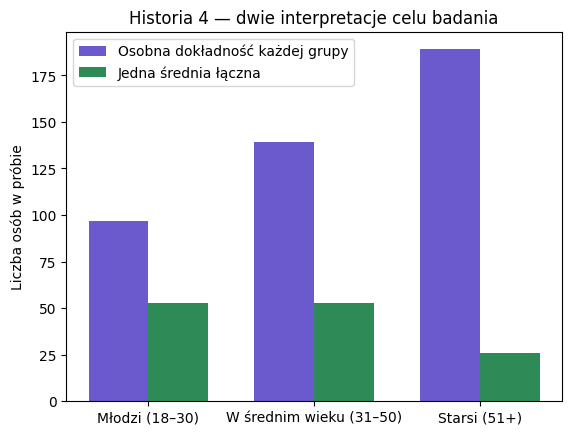

In [13]:
pozycje4 = np.arange(len(nazwy4))
fig, ax = plt.subplots()
ax.bar(pozycje4 - 0.18, n_warstwy4, width=0.36, color="slateblue", label="Osobna dokładność każdej grupy")
ax.bar(pozycje4 + 0.18, podzial4, width=0.36, color="seagreen", label="Jedna średnia łączna")
ax.set_xticks(pozycje4, nazwy4)
ax.set(ylabel="Liczba osób w próbie", title="Historia 4 — dwie interpretacje celu badania")
ax.legend()
plt.show()

### Wniosek
**425 osób** potrzeba według sposobu liczenia każdej grupy osobno: 97 młodych, 139 w średnim wieku i 189 starszych. Jeśli interesuje nas **jedna średnia dla całej firmy**, przy proporcjonalnym wyborze osób wystarcza około **132 osób**. Różnica wynika z innego celu badania.